# Train a quantum and classical neural network on Iris

This notebook follows the four-qubit Iris QNN in `PennyLane_QNN_Detailed_Guide.ipynb` and adds a trainable classical neural network for comparison. Both models use the **real Iris dataset**, with four flower measurements as inputs and three species as classes.

We train both models from fresh random starting weights. They share the same training, validation, and held-out test examples. The QNN runs on PennyLane's CPU simulator, so the experiment needs no quantum hardware. A small test set is useful for learning the workflow, but one run does not establish that either model is generally better.

## 1. Set up the tools

PennyLane defines and simulates the quantum circuit. Scikit-learn provides the Iris measurements, stratified data splitting, and feature scaling. PyTorch supplies the classical neural network and its backpropagation optimizer.

Install this project's packages with `python -m pip install -r requirements.txt`, then run the notebook in that same Python environment.

In [1]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
import torch

from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, balanced_accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
print('PennyLane:', qml.__version__)
print('PyTorch:', torch.__version__)
print('Running on the CPU; no quantum hardware is used.')

PennyLane: 0.45.1
PyTorch: 2.14.1+cpu
Running on the CPU; no quantum hardware is used.


## 2. Load the Iris data

Iris is a real, small teaching dataset with 150 measured flowers. Each flower has four features: sepal length, sepal width, petal length, and petal width. The label is one of three species: setosa, versicolor, or virginica.

The QNN will use one qubit for each feature. The classical network will receive those same four measurements as ordinary numbers.

In [2]:
iris = load_iris()
X_raw = iris.data.astype(np.float64)
y = iris.target.astype(np.int64)
feature_names = iris.feature_names
class_names = iris.target_names
n_features = X_raw.shape[1]
n_classes = len(class_names)

print('Feature matrix shape:', X_raw.shape, '(flowers, measurements)')
print('Species:', list(class_names))
print('Examples per species:', dict(zip(class_names, np.bincount(y))))
print('First flower measurements:', dict(zip(feature_names, X_raw[0])))
print('First flower label:', class_names[y[0]])

Feature matrix shape: (150, 4) (flowers, measurements)
Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Examples per species: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}
First flower measurements: {'sepal length (cm)': np.float64(5.1), 'sepal width (cm)': np.float64(3.5), 'petal length (cm)': np.float64(1.4), 'petal width (cm)': np.float64(0.2)}
First flower label: setosa


## 3. Split the examples, then scale the features

We use a stratified 60% / 20% / 20% split: 90 training flowers, 30 validation flowers, and 30 test flowers. Stratification keeps all three species represented in each group.

The training examples update model parameters. Validation examples help choose the best training checkpoint. We save the test examples for the final comparison. The scaler is fitted on training measurements only, so information from the held-out groups does not affect preprocessing.

For the QNN, each standardized measurement is passed through `arctan` to make a rotation angle between `-?/2` and `?/2`. The classical network uses the standardized measurements directly.

In [3]:
all_indices = np.arange(len(y))
train_val_indices, test_indices = train_test_split(
    all_indices, test_size=0.20, stratify=y, random_state=SEED,
)
train_indices, validation_indices = train_test_split(
    train_val_indices, test_size=0.25,
    stratify=y[train_val_indices], random_state=SEED + 1,
)

X_train_raw, y_train = X_raw[train_indices], y[train_indices]
X_validation_raw, y_validation = X_raw[validation_indices], y[validation_indices]
X_test_raw, y_test = X_raw[test_indices], y[test_indices]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_validation_scaled = scaler.transform(X_validation_raw)
X_test_scaled = scaler.transform(X_test_raw)

# The quantum circuit expects radians. The MLP can use the scaled measurements directly.
X_train_angles = np.arctan(X_train_scaled)
X_validation_angles = np.arctan(X_validation_scaled)
X_test_angles = np.arctan(X_test_scaled)

print(f'Train: {len(y_train)} flowers; validation: {len(y_validation)}; test: {len(y_test)}')
print('Train class counts:', np.bincount(y_train))
print('Four QNN angles for the first flower:', X_train_angles[0])
print('Scaler means, learned from training flowers:', scaler.mean_)

Train: 90 flowers; validation: 30; test: 30
Train class counts: [30 30 30]
Four QNN angles for the first flower: [-0.1605  1.254  -0.9109 -0.8109]
Scaler means, learned from training flowers: [5.8344 3.0378 3.7389 1.1789]


## 4. Build the four-feature QNN

A **qubit** is the basic unit of information in this circuit. We use four qubits, one for each Iris measurement. `AngleEmbedding` encodes each measurement as a Y-axis rotation.

The circuit repeats three trainable layers. On each qubit, a learned Y rotation and a learned X rotation adjust the state. A chain of CNOT gates then couples neighboring qubits (0 to 1, 1 to 2, and 2 to 3), letting the circuit combine information from different features. The circuit measures Pauli-Z on all four qubits, producing four numeric features.

A small classical linear readout maps those four measurements to three class scores (called logits). The model has 24 trainable gate angles plus 15 readout weights and biases, for 39 trainable parameters. `shots=None` gives exact simulator expectation values. Backpropagation differentiates through the simulator; this is a convenient CPU training method, not a hardware measurement procedure.

In [4]:
N_QUBITS = n_features
N_LAYERS = 3
WIRES = tuple(range(N_QUBITS))
device = qml.device('default.qubit', wires=N_QUBITS, shots=None, seed=SEED)


def circuit_operations(inputs, theta):
    qml.AngleEmbedding(inputs, wires=WIRES, rotation='Y')
    for layer in range(N_LAYERS):
        for wire in WIRES:
            qml.RY(theta[layer, wire, 0], wires=wire)
            qml.RX(theta[layer, wire, 1], wires=wire)
        for wire in range(N_QUBITS - 1):
            qml.CNOT(wires=[wire, wire + 1])


@qml.qnode(device, interface='autograd', diff_method='backprop')
def quantum_circuit(inputs, theta):
    circuit_operations(inputs, theta)
    return tuple(qml.expval(qml.PauliZ(wire)) for wire in WIRES)


def quantum_features(inputs, theta):
    # For a batch, each measurement has shape (batch,); stack them as (batch, 4).
    return pnp.stack(quantum_circuit(inputs, theta), axis=-1)


def logits(inputs, theta, W, b):
    return quantum_features(inputs, theta) @ W + b


def log_softmax(scores):
    # Subtracting the largest score keeps exponentials numerically stable.
    shifted = scores - pnp.max(scores, axis=-1, keepdims=True)
    return shifted - pnp.log(pnp.sum(pnp.exp(shifted), axis=-1, keepdims=True))


def predict_proba(inputs, theta, W, b):
    return pnp.exp(log_softmax(logits(inputs, theta, W, b)))


def cross_entropy(theta, W, b, inputs, targets):
    log_probabilities = log_softmax(logits(inputs, theta, W, b))
    return -pnp.mean(pnp.sum(targets * log_probabilities, axis=-1))


def one_hot(labels):
    return pnp.array(np.eye(n_classes)[labels], requires_grad=False)


X_train_qnn = pnp.array(X_train_angles, requires_grad=False)
X_validation_qnn = pnp.array(X_validation_angles, requires_grad=False)
X_test_qnn = pnp.array(X_test_angles, requires_grad=False)
Y_train = one_hot(y_train)
Y_validation = one_hot(y_validation)
Y_test = one_hot(y_test)

print('QNN input shape:', X_train_qnn.shape)
print('QNN target shape:', Y_train.shape)
print('Circuit:', N_QUBITS, 'qubits,', N_LAYERS, 'trainable layers')

QNN input shape: (90, 4)
QNN target shape: (90, 3)
Circuit: 4 qubits, 3 trainable layers


### Initialize the QNN and check its outputs

The angle tensor stores two trainable rotations for each qubit in each layer: 3 layers ? 4 qubits ? 2 rotations = 24 values. The readout matrix has shape 4 by 3, with three additional bias values.

The loss uses **cross-entropy**: it is smaller when the model gives a high probability to the correct species. Softmax converts the three logits into probabilities that sum to one. The four quantum measurements are features for the readout; they are not themselves the three species probabilities.

In [5]:
def initialize_parameters(seed=SEED):
    rng = np.random.default_rng(seed)
    theta = pnp.array(
        rng.normal(0.0, 0.25, size=(N_LAYERS, N_QUBITS, 2)),
        requires_grad=True,
    )
    W = pnp.array(rng.normal(0.0, 0.25, size=(N_QUBITS, n_classes)), requires_grad=True)
    b = pnp.array(np.zeros(n_classes), requires_grad=True)
    return theta, W, b


def copy_parameters(parameters):
    return tuple(pnp.array(value, requires_grad=True) for value in parameters)


theta0, W0, b0 = initialize_parameters()
initial_probabilities = predict_proba(X_train_qnn[:3], theta0, W0, b0)
print('Trainable parameters:', theta0.size + W0.size + b0.size)
print('Initial probabilities for three flowers:')
print(initial_probabilities)
print('Each row sums to:', initial_probabilities.sum(axis=1))

Trainable parameters: 39
Initial probabilities for three flowers:
[[0.2962 0.3125 0.3914]
 [0.3036 0.3166 0.3798]
 [0.3102 0.3145 0.3753]]
Each row sums to: [1. 1. 1.]


## 5. Train the QNN

One training step compares predictions for all 90 training flowers with their correct species. This is **full-batch training**. PennyLane differentiates the cross-entropy through the analytic simulator, and Adam uses those gradients to update both the quantum angles and the classical readout.

After each update, we check validation loss. We copy the parameters whenever validation loss improves, then restore the best copy after 120 updates. The test flowers are not used to choose the checkpoint.

In [6]:
EPOCHS = 120
LEARNING_RATE = 0.05


def evaluate_qnn(inputs, labels, targets, parameters):
    probabilities = np.asarray(predict_proba(inputs, *parameters), dtype=float)
    predictions = probabilities.argmax(axis=1)
    loss = float(cross_entropy(*parameters, inputs, targets))
    return {
        'loss': loss,
        'accuracy': float(accuracy_score(labels, predictions)),
        'probabilities': probabilities,
        'predictions': predictions,
    }


def train_qnn(epochs=EPOCHS, learning_rate=LEARNING_RATE):
    parameters = initialize_parameters(SEED)
    optimizer = qml.AdamOptimizer(stepsize=learning_rate)
    history = []
    best_parameters = copy_parameters(parameters)
    best_validation_loss = evaluate_qnn(
        X_validation_qnn, y_validation, Y_validation, parameters,
    )['loss']
    best_epoch = 0

    for epoch in range(epochs + 1):
        if epoch > 0:
            parameters = tuple(optimizer.step(
                lambda theta, W, b: cross_entropy(theta, W, b, X_train_qnn, Y_train),
                *parameters,
            ))
        train_metrics = evaluate_qnn(X_train_qnn, y_train, Y_train, parameters)
        validation_metrics = evaluate_qnn(
            X_validation_qnn, y_validation, Y_validation, parameters,
        )
        history.append({
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'validation_loss': validation_metrics['loss'],
            'train_accuracy': train_metrics['accuracy'],
            'validation_accuracy': validation_metrics['accuracy'],
        })
        if validation_metrics['loss'] < best_validation_loss:
            best_validation_loss = validation_metrics['loss']
            best_parameters = copy_parameters(parameters)
            best_epoch = epoch
        if epoch == 0 or epoch % 20 == 0 or epoch == epochs:
            print(
                f'Epoch {epoch:3d}: train loss {train_metrics["loss"]:.4f}, '
                f'validation loss {validation_metrics["loss"]:.4f}, '
                f'train accuracy {train_metrics["accuracy"]:.1%}, '
                f'validation accuracy {validation_metrics["accuracy"]:.1%}'
            )
    return best_parameters, history, best_epoch


qnn_start = time.perf_counter()
qnn_best_parameters, qnn_history, qnn_best_epoch = train_qnn()
qnn_training_seconds = time.perf_counter() - qnn_start
print(f'Best validation checkpoint: epoch {qnn_best_epoch}')
print(f'QNN training time on this computer: {qnn_training_seconds:.1f} seconds')

Epoch   0: train loss 1.1827, validation loss 1.1831, train accuracy 4.4%, validation accuracy 6.7%
Epoch  20: train loss 0.5212, validation loss 0.5263, train accuracy 74.4%, validation accuracy 80.0%
Epoch  40: train loss 0.3028, validation loss 0.2916, train accuracy 87.8%, validation accuracy 93.3%
Epoch  60: train loss 0.1948, validation loss 0.1763, train accuracy 95.6%, validation accuracy 100.0%
Epoch  80: train loss 0.1355, validation loss 0.1149, train accuracy 96.7%, validation accuracy 100.0%
Epoch 100: train loss 0.1075, validation loss 0.0821, train accuracy 98.9%, validation accuracy 100.0%
Epoch 120: train loss 0.0936, validation loss 0.0649, train accuracy 97.8%, validation accuracy 100.0%
Best validation checkpoint: epoch 119
QNN training time on this computer: 7.6 seconds


### Full trained QNN circuit

This diagram shows the **complete three-layer circuit** used by the classifier for one Iris flower. Read from left to right: the first `RY` gates encode the four measurements, each repeated block applies learned `RY` and `RX` rotations followed by a chain of CNOT gates, and the final symbols measure Pauli-Z on all four qubits. The classical 4-to-3 readout is outside the quantum circuit, so it is not drawn here.

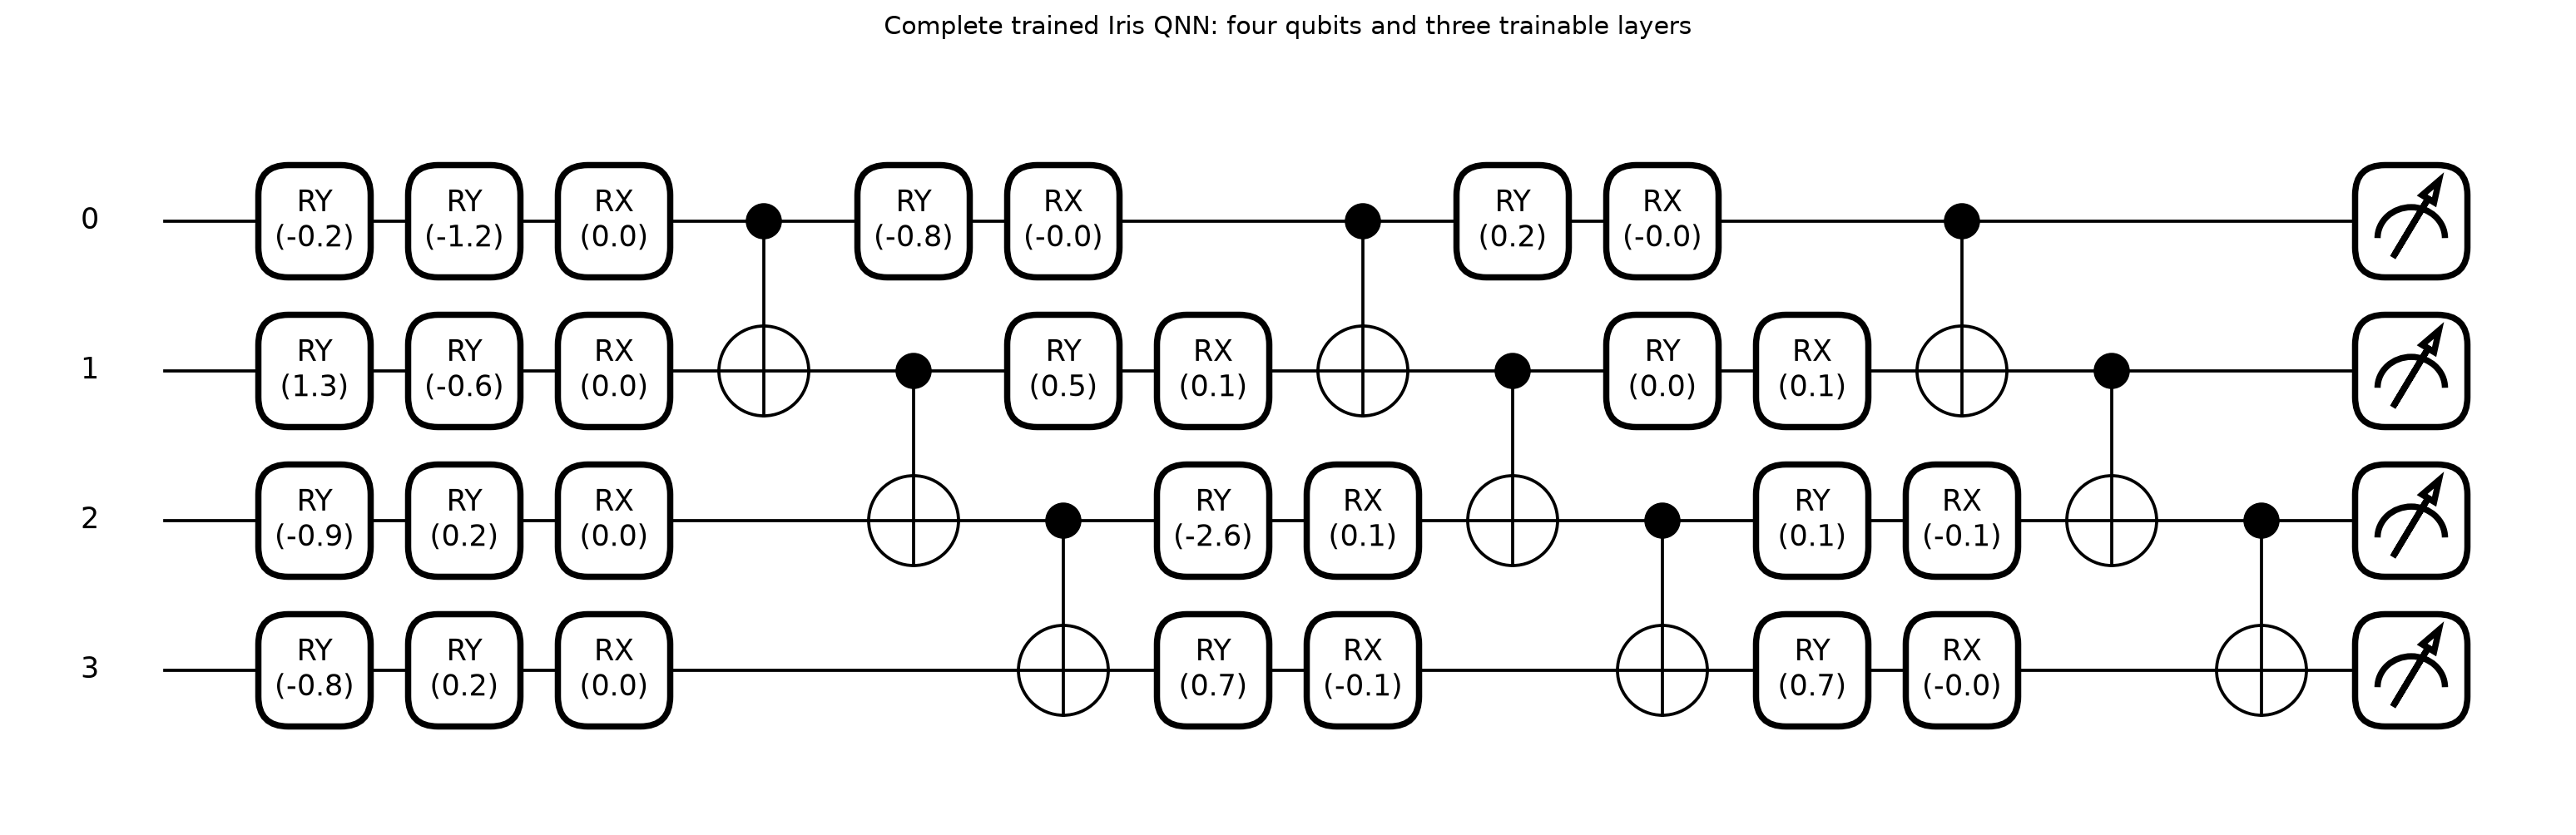

In [ ]:
# Draw every operation in the trained three-layer circuit.
import importlib
import pennylane.drawer.mpldrawer as mpldrawer

# Refresh PennyLane's cached optional import if Matplotlib was installed
# after PennyLane was first imported in this notebook session.
if not mpldrawer.has_mpl:
    importlib.reload(mpldrawer)

fig = plt.figure(figsize=(28, 5.2))
fig, ax = qml.draw_mpl(
    quantum_circuit, fig=fig, decimals=1, level='device',
    wire_order=WIRES, show_all_wires=True,
)(X_train_qnn[0], qnn_best_parameters[0])
ax.set_title('Complete trained Iris QNN: four qubits and three trainable layers', pad=18)
fig.savefig('qnn_iris_circuit.png', dpi=180, bbox_inches='tight')
fig.savefig('qnn_iris_circuit.svg', bbox_inches='tight')
plt.show()


### Follow the QNN training

Loss measures how strongly the model favors the correct class; accuracy counts how often its top-scoring class is correct. The validation curves help show whether progress on training examples also carries over to examples not used for updates.

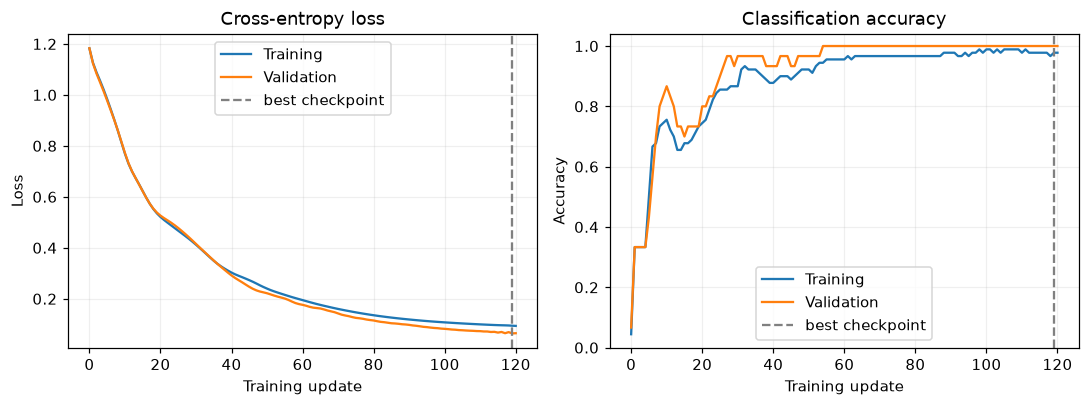

In [8]:
epochs_axis = [row['epoch'] for row in qnn_history]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for split, key in [('Training', 'train'), ('Validation', 'validation')]:
    axes[0].plot(epochs_axis, [row[f'{key}_loss'] for row in qnn_history], label=split)
    axes[1].plot(epochs_axis, [row[f'{key}_accuracy'] for row in qnn_history], label=split)
for ax in axes:
    ax.axvline(qnn_best_epoch, color='gray', linestyle='--', label='best checkpoint')
    ax.set_xlabel('Training update')
    ax.legend()
    ax.grid(alpha=0.2)
axes[0].set(title='Cross-entropy loss', ylabel='Loss')
axes[1].set(title='Classification accuracy', ylabel='Accuracy', ylim=(0, 1.04))
fig.tight_layout()
plt.show()

## 6. Define the classical neural network

The classical comparison is a small **multilayer perceptron (MLP)**. It has four input values, a hidden layer with four `tanh` units, and three output scores?one for each Iris species. `tanh` lets the hidden layer learn curved patterns; the final scores are logits, which cross-entropy turns into class probabilities during training.

This MLP has 35 trainable weights and biases. The QNN has 39, so they have similar parameter counts. The MLP receives the standardized measurements directly; the QNN converts those same standardized measurements into rotation angles first.

In [9]:
class ClassicalIrisNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = torch.nn.Linear(n_features, 4)
        self.output = torch.nn.Linear(4, n_classes)

    def forward(self, features):
        hidden = torch.tanh(self.hidden(features))
        return self.output(hidden)  # Return logits; CrossEntropyLoss applies log-softmax.


def as_float_tensor(array):
    return torch.as_tensor(array, dtype=torch.float32)


def as_label_tensor(array):
    return torch.as_tensor(array, dtype=torch.long)

X_train_mlp = as_float_tensor(X_train_scaled)
X_validation_mlp = as_float_tensor(X_validation_scaled)
X_test_mlp = as_float_tensor(X_test_scaled)
torch_y_train = as_label_tensor(y_train)
torch_y_validation = as_label_tensor(y_validation)
torch_y_test = as_label_tensor(y_test)

torch.manual_seed(SEED)
mlp_model = ClassicalIrisNN()
mlp_parameter_count = sum(parameter.numel() for parameter in mlp_model.parameters())
print('MLP trainable parameters:', mlp_parameter_count)
print('First flower output shape:', tuple(mlp_model(X_train_mlp[:1]).shape))

MLP trainable parameters: 35
First flower output shape: (1, 3)


### Classical network picture

Each circle represents an input feature, hidden unit, or output class. Arrows show which values can affect the next layer. Every input connects to every hidden unit, and every hidden unit connects to every class score. The labels `c0`, `c1`, and `c2` correspond to the three species listed below the diagram.

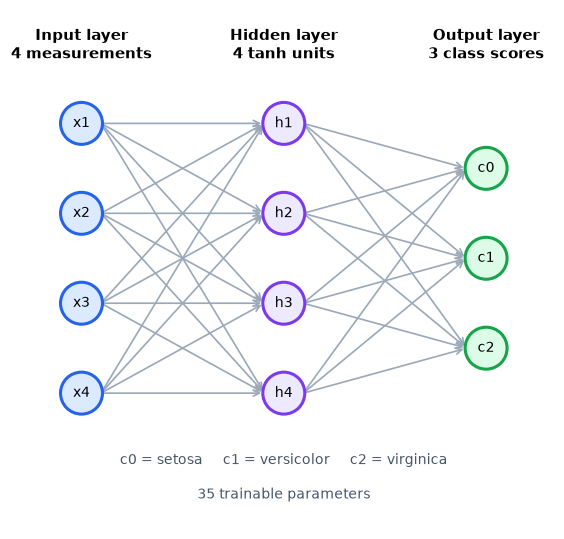

In [10]:
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(9, 5))
input_nodes = [(0, 1.65), (0, 1.05), (0, 0.45), (0, -0.15)]
hidden_nodes = [(1.35, 1.65), (1.35, 1.05), (1.35, 0.45), (1.35, -0.15)]
output_nodes = [(2.7, 1.35), (2.7, 0.75), (2.7, 0.15)]

for x1, y1 in input_nodes:
    for x2, y2 in hidden_nodes:
        ax.annotate('', xy=(x2 - 0.13, y2), xytext=(x1 + 0.13, y1),
                    arrowprops=dict(arrowstyle='->', color='#9aa8b8', lw=1.1))
for x1, y1 in hidden_nodes:
    for x2, y2 in output_nodes:
        ax.annotate('', xy=(x2 - 0.13, y2), xytext=(x1 + 0.13, y1),
                    arrowprops=dict(arrowstyle='->', color='#9aa8b8', lw=1.1))

node_layers = [
    (input_nodes, ['x1', 'x2', 'x3', 'x4'], '#dbeafe', '#2563eb'),
    (hidden_nodes, ['h1', 'h2', 'h3', 'h4'], '#ede9fe', '#7c3aed'),
    (output_nodes, ['c0', 'c1', 'c2'], '#dcfce7', '#16a34a'),
]
for positions, labels, fill, edge in node_layers:
    for (x_pos, y_pos), label in zip(positions, labels):
        ax.add_patch(Circle((x_pos, y_pos), 0.14, facecolor=fill,
                            edgecolor=edge, linewidth=2, zorder=3))
        ax.text(x_pos, y_pos, label, ha='center', va='center', fontsize=9, zorder=4)

ax.text(0, 2.05, 'Input layer\n4 measurements', ha='center', va='bottom', weight='bold')
ax.text(1.35, 2.05, 'Hidden layer\n4 tanh units', ha='center', va='bottom', weight='bold')
ax.text(2.7, 2.05, 'Output layer\n3 class scores', ha='center', va='bottom', weight='bold')
ax.text(1.35, -0.55, 'c0 = setosa     c1 = versicolor     c2 = virginica',
        ha='center', va='top', fontsize=9, color='#475569')
ax.text(1.35, -0.78, f'{mlp_parameter_count} trainable parameters',
        ha='center', va='top', fontsize=9, color='#475569')
ax.set_xlim(-0.45, 3.15)
ax.set_ylim(-1.05, 2.4)
ax.set_aspect('equal')
ax.axis('off')
fig.tight_layout()
plt.show()

## 7. Train the classical network

We use the same training flowers, validation flowers, 120-update budget, full-batch cross-entropy, Adam optimizer, and learning rate as for the QNN. The MLP's gradients come from ordinary backpropagation through its two dense layers. As with the QNN, we keep the model state with the lowest validation loss.

In [11]:
def evaluate_mlp(model, features, labels):
    model.eval()
    with torch.no_grad():
        scores = model(features)
        loss = torch.nn.functional.cross_entropy(scores, labels).item()
        predictions = scores.argmax(dim=1).cpu().numpy()
    return {
        'loss': float(loss),
        'accuracy': float(accuracy_score(labels.cpu().numpy(), predictions)),
        'predictions': predictions,
    }


def train_mlp(model, epochs=EPOCHS, learning_rate=LEARNING_RATE):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    best_state = copy.deepcopy(model.state_dict())
    best_validation_loss = evaluate_mlp(
        model, X_validation_mlp, torch_y_validation,
    )['loss']
    best_epoch = 0

    for epoch in range(epochs + 1):
        if epoch > 0:
            model.train()
            optimizer.zero_grad()
            scores = model(X_train_mlp)
            loss = torch.nn.functional.cross_entropy(scores, torch_y_train)
            loss.backward()
            optimizer.step()
        train_metrics = evaluate_mlp(model, X_train_mlp, torch_y_train)
        validation_metrics = evaluate_mlp(model, X_validation_mlp, torch_y_validation)
        history.append({
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'validation_loss': validation_metrics['loss'],
            'train_accuracy': train_metrics['accuracy'],
            'validation_accuracy': validation_metrics['accuracy'],
        })
        if validation_metrics['loss'] < best_validation_loss:
            best_validation_loss = validation_metrics['loss']
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        if epoch == 0 or epoch % 20 == 0 or epoch == epochs:
            print(
                f'Epoch {epoch:3d}: train loss {train_metrics["loss"]:.4f}, '
                f'validation loss {validation_metrics["loss"]:.4f}, '
                f'train accuracy {train_metrics["accuracy"]:.1%}, '
                f'validation accuracy {validation_metrics["accuracy"]:.1%}'
            )
    model.load_state_dict(best_state)
    return history, best_epoch


mlp_start = time.perf_counter()
mlp_history, mlp_best_epoch = train_mlp(mlp_model)
mlp_training_seconds = time.perf_counter() - mlp_start
print(f'Best validation checkpoint: epoch {mlp_best_epoch}')
print(f'MLP training time on this computer: {mlp_training_seconds:.1f} seconds')

Epoch   0: train loss 1.0671, validation loss 1.0760, train accuracy 27.8%, validation accuracy 23.3%
Epoch  20: train loss 0.2733, validation loss 0.2337, train accuracy 88.9%, validation accuracy 96.7%
Epoch  40: train loss 0.0946, validation loss 0.0675, train accuracy 96.7%, validation accuracy 100.0%
Epoch  60: train loss 0.0660, validation loss 0.0534, train accuracy 96.7%, validation accuracy 96.7%
Epoch  80: train loss 0.0581, validation loss 0.0361, train accuracy 97.8%, validation accuracy 100.0%
Epoch 100: train loss 0.0546, validation loss 0.0289, train accuracy 97.8%, validation accuracy 100.0%
Epoch 120: train loss 0.0522, validation loss 0.0245, train accuracy 97.8%, validation accuracy 100.0%
Best validation checkpoint: epoch 120
MLP training time on this computer: 1.4 seconds


## 8. Compare on the held-out Iris test flowers

The test set was not used to update either model or choose its checkpoint. We compare test accuracy (the fraction of correctly classified flowers) and cross-entropy (how well the predicted probabilities favor the correct species). Parameter counts provide a rough size comparison.

A single split of 30 flowers gives a useful classroom example, not a strong statistical result. Small score differences can change when the split or initialization changes.

In [12]:
qnn_test_metrics = evaluate_qnn(
    X_test_qnn, y_test, Y_test, qnn_best_parameters,
)
mlp_test_metrics = evaluate_mlp(mlp_model, X_test_mlp, torch_y_test)
qnn_parameter_count = int(theta0.size + W0.size + b0.size)

print(f'{"Model":<24} {"Parameters":>10} {"Best epoch":>12} {"Test accuracy":>15} {"Test loss":>12}')
print('-' * 78)
print(f'{"Quantum neural network":<24} {qnn_parameter_count:>10} {qnn_best_epoch:>12} '
      f'{qnn_test_metrics["accuracy"]:>14.1%} {qnn_test_metrics["loss"]:>12.4f}')
print(f'{"Classical MLP":<24} {mlp_parameter_count:>10} {mlp_best_epoch:>12} '
      f'{mlp_test_metrics["accuracy"]:>14.1%} {mlp_test_metrics["loss"]:>12.4f}')
print('Test flowers:', len(y_test), '| classes:', list(class_names))

Model                    Parameters   Best epoch   Test accuracy    Test loss
------------------------------------------------------------------------------
Quantum neural network           39          119          96.7%       0.1276
Classical MLP                    35          120         100.0%       0.0568
Test flowers: 30 | classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## What to take away

- Both models use all four Iris measurements to classify the same three species.
- The QNN converts features to rotations, processes them with a four-qubit circuit, and uses a small classical readout.
- The MLP processes standardized measurements through dense layers.
- Both models use the same data split, loss, optimizer settings, and validation checkpoint rule; their parameter counts are similar.
- The QNN is simulated on a classical CPU. This experiment compares two learning models on one small dataset; it does not demonstrate quantum advantage.

**Try next:** change the hidden width or circuit depth, repeat the comparison with several random seeds, and report the mean and spread of test results.